# 🧙‍♂️ Задача 5: Безопасность гномьих шахт (Яндекс Контест AI 2026)
### Обнаружение препятствий в габарите движения автономной вагонетки по облакам точек MaDAR

---

### 📋 Описание задачи и условия:
Гномы создали автономные вагонетки для перевозки руды в шахтах. Вагонетки оснащены **MaDAR** — магическим 3D-лидаром.
Наша задача — для каждой точки облака определить, находится ли она в **габарите движения вагонетки** (метка 1) или является фоном (метка 0).

#### 📐 Геометрия габарита движения:
* **Координатная система сканера:** $X$ — вперёд, $Y$ — влево, $Z$ — вверх.
* **Расположение сканера:** высота **0.85 м** над основанием рельсов ($h=0$).
* **Колея пути:** **0.60 м** (рельсы расположены на $Y \approx \pm 0.30$ м).
* **Поперечное сечение габарита:**
  * По ширине: **по 0.55 м** в обе стороны от оси пути ($|Y - Y_{\text{track}}| \le 0.55$ м, ширина 1.10 м).
  * По высоте: от **0.16 м до 1.15 м** над основанием рельсов.
  * В системе координат сканера (для прямолинейного участка):
    $$Z_{\min} = 0.16 - 0.85 = -0.69\text{ м}$$
    $$Z_{\max} = 1.15 - 0.85 = +0.30\text{ м}$$
    $$|Y| \le 0.55\text{ м}$$
* Если объект попадает в габарит лишь частично (например, гном, стоящий на краю пути), метку **1** получает **только выступающая в габарит часть**!

#### 🎯 Целевая метрика:
$$S = R \cdot P \cdot (1 - F)^2$$
* $R$ (**Полнота / Recall**): доля обнаруженных предметов по 3 диапазонам дальности (0–10м, 10–25м, 25–60м). Предмет считается **обнаруженным в кадре**, если правильно отмечена **хотя бы одна** его точка с меткой 1!
* $P$ (**Точность / Precision**): средняя точность $TP / (TP + FP)$ по кадрам с непустым ответом.
* $F$ (**Доля ложных тревог**): доля секундных отрезков (по 10 кадров), где по разметке препятствий нет, но алгоритм отметил хотя бы одну точку как 1.
* **Критический вывод:** множитель $(1 - F)^2$ чрезвычайно сильно штрафует ложные тревоги! Ложные тревоги на пустых участках должны быть сведены к минимуму (в идеале $F \to 0$).

#### 📦 Формат ответа:
* Бинарный файл `predictions.bin`: по одному биту на каждую точку (`bitorder="little"`).
* Размер файла для test (1000 клипов по 10 сканов) — ровно **5 645 885 байт**.


In [1]:
# 1. Импорт библиотек и проверка окружения
import os
import glob
import math
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import scipy
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from tqdm.auto import tqdm

# Настройка визуализации
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

# Проверка путей к данным
DATA_DIR = Path("5_task") if Path("5_task").exists() else Path(".")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print(f"Пути к данным:")
print(f"  Train: {TRAIN_DIR} (файлов: {len(list(TRAIN_DIR.glob('*.npz')))})")
print(f"  Val:   {VAL_DIR}   (файлов: {len(list(VAL_DIR.glob('*.npz')))})")
print(f"  Test:  {TEST_DIR}  (файлов: {len(list(TEST_DIR.glob('*.npz')))})")


Пути к данным:
  Train: train (файлов: 80)
  Val:   val   (файлов: 24)
  Test:  test  (файлов: 1000)


C:\Users\nikki\MLProjects\ArtificleIntellegenceYandexContest2026\5_task\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 2. Загрузка тренировочных данных в pandas DataFrame
train_files = sorted(TRAIN_DIR.glob("*.npz"))
sample_file = train_files[0]
print(f"Загружаем последовательность: {sample_file.name}")

with np.load(sample_file) as data:
    points = data['points']
    frame_offsets = data['frame_offsets']
    labels = data['labels']
    object_ids = data['object_ids']

print(f"Общее число точек в файле: {len(points):,}")
print(f"Число сканов (кадров): {len(frame_offsets) - 1}")

# Сформируем массив номеров кадров для каждой точки
frame_indices = np.empty(len(points), dtype=np.int32)
for f_idx in range(len(frame_offsets) - 1):
    lo, hi = frame_offsets[f_idx], frame_offsets[f_idx + 1]
    frame_indices[lo:hi] = f_idx

# Создаем DataFrame для анализа тренировочных данных
df = pd.DataFrame({
    'x': points[:, 0],
    'y': points[:, 1],
    'z': points[:, 2],
    'label': labels,
    'object_id': object_ids,
    'frame_idx': frame_indices
})


Загружаем последовательность: 0643128fea0e961e.npz
Общее число точек в файле: 1,357,762
Число сканов (кадров): 300


### 📊 Анализ тренировочных данных: `head()`, `describe()`, `info()`
Выводим основные статистики датасета, типы полей, распределение координат и меток.

In [3]:
# 3.1 Вывод структуры данных: df.info()
print("=" * 60)
print("  INFO О ТРЕНИРОВОЧНЫХ ДАННЫХ:")
print("=" * 60)
df.info()


  INFO О ТРЕНИРОВОЧНЫХ ДАННЫХ:
<class 'pandas.DataFrame'>
RangeIndex: 1357762 entries, 0 to 1357761
Data columns (total 6 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   x          1357762 non-null  float32
 1   y          1357762 non-null  float32
 2   z          1357762 non-null  float32
 3   label      1357762 non-null  uint8  
 4   object_id  1357762 non-null  int32  
 5   frame_idx  1357762 non-null  int32  
dtypes: float32(3), int32(2), uint8(1)
memory usage: 27.2 MB


In [4]:
# 3.2 Первые строки тренировочного датасета: df.head(10)
print("=" * 60)
print("  ПЕРВЫЕ 10 СТРОК ДАТАСЕТА (df.head(10)):")
print("=" * 60)
df.head(10)


  ПЕРВЫЕ 10 СТРОК ДАТАСЕТА (df.head(10)):


,x,y,z,label,object_id,frame_idx
0,3.775506,3.168026,0.692666,0,-1,0
1,3.809608,3.149471,0.694680,0,-1,0
2,3.881751,3.161628,0.703601,0,-1,0
3,3.945345,3.165733,0.710915,0,-1,0
4,4.015621,3.174148,0.719377,0,-1,0
5,4.083922,3.179906,0.727429,0,-1,0
6,4.118103,3.158437,0.729385,0,-1,0
7,4.173500,3.152737,0.735095,0,-1,0
8,4.215107,3.136036,0.738366,0,-1,0
9,4.265836,3.125594,0.743230,0,-1,0


In [5]:
# 3.3 Описательная статистика: df.describe()
print("=" * 60)
print("  ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ (df.describe()):")
print("=" * 60)
df.describe()


  ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ (df.describe()):


,x,y,z,label,object_id,frame_idx
count,1.357762e+06,1.357762e+06,1.357762e+06,1.357762e+06,1.357762e+06,1.357762e+06
mean,9.517406e+00,1.286482e-01,-1.288394e-01,4.397678e-03,3.518043e+04,1.491812e+02
std,8.421888e+00,3.137655e+00,1.052828e+00,6.616904e-02,5.293524e+05,8.666884e+01
min,3.863637e-01,-4.800623e+00,-3.749430e+00,0.000000e+00,-1.000000e+00,0.000000e+00
25%,4.481505e+00,-3.047970e+00,-9.263046e-01,0.000000e+00,-1.000000e+00,7.400000e+01
50%,6.339355e+00,-1.515608e-02,-5.875412e-01,0.000000e+00,-1.000000e+00,1.490000e+02
75%,1.073451e+01,2.948302e+00,4.479687e-01,0.000000e+00,-1.000000e+00,2.240000e+02
max,5.992589e+01,2.660742e+01,6.265999e+00,1.000000e+00,8.000001e+06,2.990000e+02


In [6]:
# 3.4 Статистика точек препятствий (label == 1): df[df['label'] == 1].describe()
print("=" * 60)
print("  СТАТИСТИКИ ТОЧЕК ВНУТРИ ГАБАРИТА (label == 1):")
print("=" * 60)
df[df['label'] == 1].describe()


  СТАТИСТИКИ ТОЧЕК ВНУТРИ ГАБАРИТА (label == 1):


,x,y,z,label,object_id,frame_idx
count,5971.000000,5971.000000,5971.000000,5971.0,5971.0,5971.000000
mean,1.520586,-0.004550,-0.107532,1.0,8000001.0,296.445319
std,1.743776,0.274466,0.042929,0.0,0.0,4.070009
min,0.386364,-0.551810,-0.196873,1.0,8000001.0,274.000000
25%,0.431670,-0.220161,-0.138630,1.0,8000001.0,296.000000
50%,0.857369,-0.007692,-0.103614,1.0,8000001.0,298.000000
75%,1.706624,0.212029,-0.071478,1.0,8000001.0,299.000000
max,11.147303,0.553130,0.184487,1.0,8000001.0,299.000000


In [7]:
# 4. Анализ распределения меток и структуры проездов
total_pts = len(df)
pos_pts = int(df['label'].sum())
neg_pts = total_pts - pos_pts

print(f"Всего точек в образце: {total_pts:,}")
print(f"Точек фона (метка 0):  {neg_pts:,} ({neg_pts / total_pts * 100:.2f}%)")
print(f"Точек в габарите (метка 1): {pos_pts:,} ({pos_pts / total_pts * 100:.2f}%)")
print(f"Уникальные ID объектов: {df['object_id'].unique()}")

# Анализ пустых проездов по всему train набору
empty_train_files = 0
total_train_pos_pts = 0
for f in train_files:
    with np.load(f) as d:
        p_cnt = int(np.sum(d['labels'] == 1))
        total_train_pos_pts += p_cnt
        if p_cnt == 0:
            empty_train_files += 1

print(f"\nСтатистика по всем {len(train_files)} тренировочным файлам:")
print(f"  Файлов без препятствий (пустые проезды): {empty_train_files} из {len(train_files)} ({empty_train_files/len(train_files)*100:.1f}%)")
print(f"  Всего точек с меткой 1 во всем train: {total_train_pos_pts:,}")


Всего точек в образце: 1,357,762
Точек фона (метка 0):  1,351,791 (99.56%)
Точек в габарите (метка 1): 5,971 (0.44%)
Уникальные ID объектов: [     -1 8000001]



Статистика по всем 80 тренировочным файлам:
  Файлов без препятствий (пустые проезды): 27 из 80 (33.8%)
  Всего точек с меткой 1 во всем train: 108,000


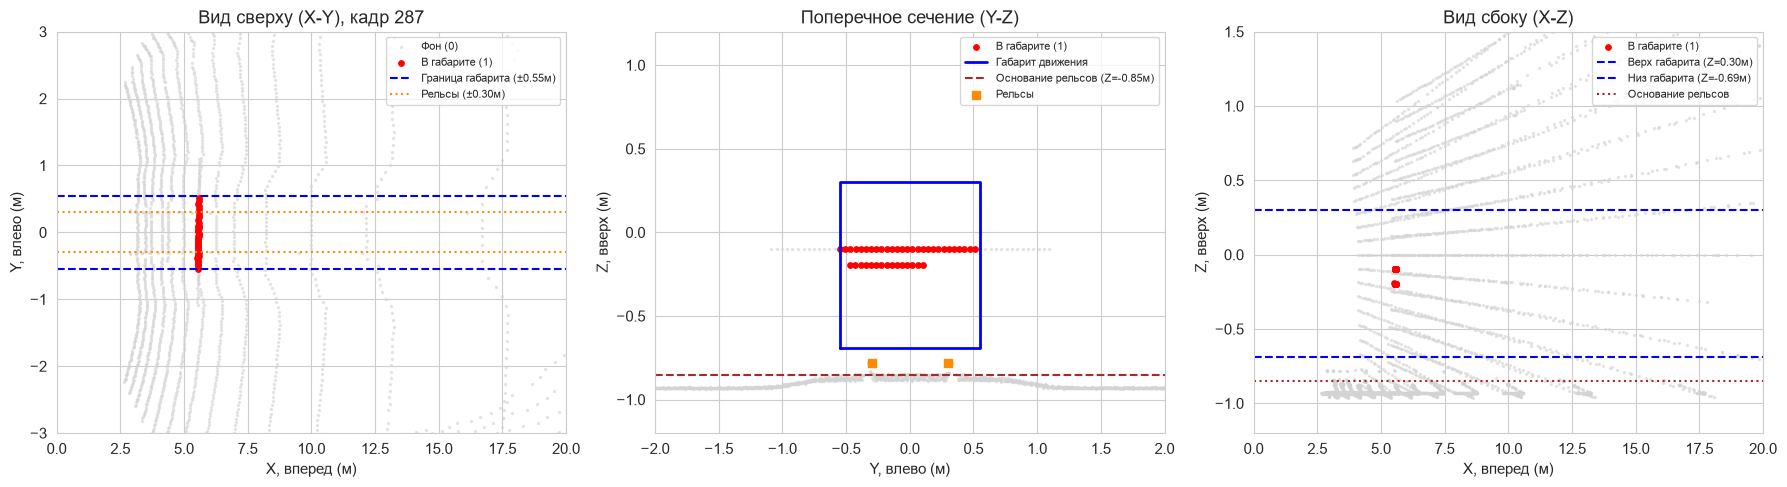

In [8]:
# 5. Визуализация облака точек и габарита движения
# Найдем кадр, где объект находится в поле зрения (например, перед вагонеткой)
frames_with_pos = df[df['label'] == 1]['frame_idx'].unique()
target_frame = frames_with_pos[len(frames_with_pos) // 2]
frame_df = df[df['frame_idx'] == target_frame]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Проекция X-Y (вид сверху)
ax = axes[0]
bg = frame_df[frame_df['label'] == 0]
pos = frame_df[frame_df['label'] == 1]
ax.scatter(bg['x'], bg['y'], s=2, c='lightgray', alpha=0.5, label='Фон (0)')
ax.scatter(pos['x'], pos['y'], s=15, c='red', label='В габарите (1)')
# Границы габарита по Y
ax.axhline(0.55, color='blue', linestyle='--', label='Граница габарита (±0.55м)')
ax.axhline(-0.55, color='blue', linestyle='--')
# Положение рельсов (колея 0.60м)
ax.axhline(0.30, color='darkorange', linestyle=':', label='Рельсы (±0.30м)')
ax.axhline(-0.30, color='darkorange', linestyle=':')
ax.set_xlabel('X, вперед (м)')
ax.set_ylabel('Y, влево (м)')
ax.set_title(f'Вид сверху (X-Y), кадр {target_frame}')
ax.set_xlim(0, 20)
ax.set_ylim(-3, 3)
ax.legend(loc='upper right', fontsize=8)

# 2. Поперечная проекция Y-Z (вид спереди / сечение габарита)
ax = axes[1]
ax.scatter(bg['y'], bg['z'], s=2, c='lightgray', alpha=0.5)
ax.scatter(pos['y'], pos['z'], s=15, c='red', label='В габарите (1)')
# Прямоугольник габарита: Y от -0.55 до 0.55, Z от -0.69 до 0.30
rect_x = [-0.55, 0.55, 0.55, -0.55, -0.55]
rect_z = [-0.69, -0.69, 0.30, 0.30, -0.69]
ax.plot(rect_x, rect_z, color='blue', linewidth=2, label='Габарит движения')
# Основание рельсов (Z = -0.85м)
ax.axhline(-0.85, color='brown', linestyle='--', label='Основание рельсов (Z=-0.85м)')
ax.scatter([-0.30, 0.30], [-0.78, -0.78], color='darkorange', s=40, marker='s', label='Рельсы')
ax.set_xlabel('Y, влево (м)')
ax.set_ylabel('Z, вверх (м)')
ax.set_title('Поперечное сечение (Y-Z)')
ax.set_xlim(-2.0, 2.0)
ax.set_ylim(-1.2, 1.2)
ax.legend(loc='upper right', fontsize=8)

# 3. Продольная проекция X-Z (вид сбоку)
ax = axes[2]
ax.scatter(bg['x'], bg['z'], s=2, c='lightgray', alpha=0.5)
ax.scatter(pos['x'], pos['z'], s=15, c='red', label='В габарите (1)')
ax.axhline(0.30, color='blue', linestyle='--', label='Верх габарита (Z=0.30м)')
ax.axhline(-0.69, color='blue', linestyle='--', label='Низ габарита (Z=-0.69м)')
ax.axhline(-0.85, color='brown', linestyle=':', label='Основание рельсов')
ax.set_xlabel('X, вперед (м)')
ax.set_ylabel('Z, вверх (м)')
ax.set_title('Вид сбоку (X-Z)')
ax.set_xlim(0, 20)
ax.set_ylim(-1.2, 1.5)
ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


In [9]:
# 5.1 Анимация проезда и облака точек по всем кадрам (вид сверху X-Y, спереди Y-Z, сбоку X-Z)
import matplotlib.animation as animation
from IPython.display import HTML
import base64

print("Генерация анимации проезда по всем кадрам...")

# Выбираем кадры с шагом для плавной анимации 30-секундного проезда (100 кадров)
anim_frames = list(range(0, len(frame_offsets) - 1, 3))

fig_anim, axes_anim = plt.subplots(1, 3, figsize=(18, 5))
ax_xy, ax_yz, ax_xz = axes_anim

# 1. Поперечное сечение Y-Z (габарит движения и рельсы)
ax_yz.plot([-0.55, 0.55, 0.55, -0.55, -0.55], [-0.69, -0.69, 0.30, 0.30, -0.69], 'b--', lw=2, label='Габарит движения')
ax_yz.axhline(-0.85, color='brown', ls=':', label='Основание рельсов (Z=-0.85м)')
ax_yz.scatter([-0.30, 0.30], [-0.78, -0.78], color='darkorange', s=40, marker='s', label='Рельсы')

# Инициализация scatter графиков:
# Фон раскрашивается непрерывной палитрой turbo по дальности (0..35 м)
# Препятствия (label == 1) выделяются ярко-красным цветом с черной обводкой
sc_xy_bg = ax_xy.scatter([], [], s=2, c=[], cmap='turbo', vmin=0, vmax=35, alpha=0.6)
sc_xy_pos = ax_xy.scatter([], [], s=30, c='red', edgecolors='black', lw=0.5, label='Препятствие (1)')
ax_xy.axhline(0.55, color='blue', ls='--', alpha=0.7, label='Габарит (±0.55м)')
ax_xy.axhline(-0.55, color='blue', ls='--', alpha=0.7)
ax_xy.set_xlim(0, 30)
ax_xy.set_ylim(-4, 4)
ax_xy.set_xlabel('X, вперед (м)')
ax_xy.set_ylabel('Y, влево (м)')
ax_xy.set_title('Вид сверху (X-Y)')
ax_xy.legend(loc='upper right', fontsize=8)

sc_yz_bg = ax_yz.scatter([], [], s=2, c=[], cmap='turbo', vmin=0, vmax=35, alpha=0.6)
sc_yz_pos = ax_yz.scatter([], [], s=30, c='red', edgecolors='black', lw=0.5, label='Препятствие (1)')
ax_yz.set_xlim(-2.5, 2.5)
ax_yz.set_ylim(-1.3, 1.3)
ax_yz.set_xlabel('Y, влево (м)')
ax_yz.set_ylabel('Z, вверх (м)')
ax_yz.set_title('Поперечное сечение (Y-Z)')
ax_yz.legend(loc='upper right', fontsize=8)

sc_xz_bg = ax_xz.scatter([], [], s=2, c=[], cmap='turbo', vmin=0, vmax=35, alpha=0.6)
sc_xz_pos = ax_xz.scatter([], [], s=30, c='red', edgecolors='black', lw=0.5, label='Препятствие (1)')
ax_xz.axhline(0.30, color='blue', ls='--', alpha=0.7, label='Верх габарита (Z=0.30м)')
ax_xz.axhline(-0.69, color='blue', ls='--', alpha=0.7, label='Низ габарита (Z=-0.69м)')
ax_xz.axhline(-0.85, color='brown', ls=':', alpha=0.7, label='Основание рельсов')
ax_xz.set_xlim(0, 30)
ax_xz.set_ylim(-1.3, 1.8)
ax_xz.set_xlabel('X, вперед (м)')
ax_xz.set_ylabel('Z, вверх (м)')
ax_xz.set_title('Вид сбоку (X-Z)')
ax_xz.legend(loc='upper right', fontsize=8)

# Цветовая шкала дальности
cbar = fig_anim.colorbar(sc_xy_bg, ax=axes_anim, orientation='horizontal', fraction=0.03, pad=0.15)
cbar.set_label('Дальность до сканера, м (палитра точек фона)')

title_anim = fig_anim.suptitle('', fontsize=13, fontweight='bold')
plt.close(fig_anim)

def update_anim(frame_idx_in_anim):
    f_num = anim_frames[frame_idx_in_anim]
    lo, hi = frame_offsets[f_num], frame_offsets[f_num + 1]
    f_p, f_l = points[lo:hi], labels[lo:hi]
    
    bg_p = f_p[f_l == 0]
    pos_p = f_p[f_l == 1]
    d_bg = np.linalg.norm(bg_p, axis=1)
    
    # Обновление XY
    sc_xy_bg.set_offsets(bg_p[:, :2])
    sc_xy_bg.set_array(d_bg)
    sc_xy_pos.set_offsets(pos_p[:, :2] if len(pos_p) else np.empty((0, 2)))
    
    # Обновление YZ
    sc_yz_bg.set_offsets(bg_p[:, [1, 2]])
    sc_yz_bg.set_array(d_bg)
    sc_yz_pos.set_offsets(pos_p[:, [1, 2]] if len(pos_p) else np.empty((0, 2)))
    
    # Обновление XZ
    sc_xz_bg.set_offsets(bg_p[:, [0, 2]])
    sc_xz_bg.set_array(d_bg)
    sc_xz_pos.set_offsets(pos_p[:, [0, 2]] if len(pos_p) else np.empty((0, 2)))
    
    pos_count = len(pos_p)
    dist_info = f"{pos_p[:, 0].mean():.1f} м" if pos_count else "нет"
    title_anim.set_text(f"Кадр {f_num:03d}/300 (t = {f_num/10:.1f} с) | Точек в габарите: {pos_count} (дальность до препятствия: {dist_info})")
    return sc_xy_bg, sc_xy_pos, sc_yz_bg, sc_yz_pos, sc_xz_bg, sc_xz_pos, title_anim

anim = animation.FuncAnimation(fig_anim, update_anim, frames=len(anim_frames), interval=100, blit=False)

# Сохранение в MP4 файл
video_path = DATA_DIR / "scene_animation.mp4"
anim.save(str(video_path), writer='ffmpeg', fps=10, dpi=100)
print(f"Видео сохранено: {video_path} (размер: {video_path.stat().st_size:,} байт)")

# Отображение встроенного HTML5 плеера с кнопками Play/Pause и перемоткой
with open(video_path, "rb") as vf:
    video_b64 = base64.b64encode(vf.read()).decode("utf-8")

HTML(f"""
<div style="text-align: center; margin: 10px 0;">
  <h4>🎬 Анимация сканирования сцены (300 кадров / 30 секунд):</h4>
  <video width="95%" controls autoplay loop muted style="border: 1px solid #ccc; border-radius: 8px;">
    <source src="data:video/mp4;base64,{video_b64}" type="video/mp4">
    Ваш браузер не поддерживает встроенное видео.
  </video>
</div>
""")


Генерация анимации проезда по всем кадрам...


Видео сохранено: scene_animation.mp4 (размер: 1,682,610 байт)


In [10]:
# 5.2 Интерактивная 3D-анимация облака точек в перспективе (True 3D View)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import HTML
import base64

# ============================================================
# 📁 ВЫБОР ФАЙЛА ДЛЯ 3D-АНИМАЦИИ:
# Укажите индекс файла из train_files (0..79):
SELECTED_FILE_INDEX = 0  # 0: 0643128fea0e961e.npz (проезд к препятствию-гному)
# ============================================================

selected_path = train_files[SELECTED_FILE_INDEX]
print(f"Загрузка файла для 3D-анимации [{SELECTED_FILE_INDEX}]: {selected_path.name}")

with np.load(selected_path) as anim_data:
    anim_points = anim_data['points']
    anim_offsets = anim_data['frame_offsets']
    anim_labels = anim_data['labels']

# Выбор кадров для плавной анимации (каждый 2-й или 3-й кадр)
frames_to_show = list(range(100, len(anim_offsets) - 1, 3))

fig_3d = plt.figure(figsize=(12, 8))
ax_3d = fig_3d.add_subplot(111, projection='3d')

# Отрисовка 3D-габарита движения (каркасный параллелепипед вдоль оси пути)
def draw_3d_gauge(ax, x0=0.5, x1=20.0, y0=-0.55, y1=0.55, z0=-0.69, z1=0.30):
    for x in [x0, x1]:
        ax.plot([x, x, x, x, x], [y0, y1, y1, y0, y0], [z0, z0, z1, z1, z0], 'b--', lw=1.5, alpha=0.7)
    for y in [y0, y1]:
        for z in [z0, z1]:
            ax.plot([x0, x1], [y, y], [z, z], 'b--', lw=1.5, alpha=0.7)

draw_3d_gauge(ax_3d, x0=0.5, x1=20.0)

# Отрисовка рельсов (колея 0.60м, основание Z=-0.85м, головка Z=-0.78м)
ax_3d.plot([0, 25], [0.30, 0.30], [-0.78, -0.78], color='darkorange', lw=2.5, label='Рельсы (колея 0.60м)')
ax_3d.plot([0, 25], [-0.30, -0.30], [-0.78, -0.78], color='darkorange', lw=2.5)

# Позиция сканера MaDAR
ax_3d.scatter([0], [0], [0], color='black', s=80, marker='^', label='Сканер MaDAR (Z=0)')

# Точки фона (градиент turbo по дальности) и препятствия (красный цвет)
sc_3d_bg = ax_3d.scatter([], [], [], s=3, c=[], cmap='turbo', vmin=0, vmax=25, alpha=0.5)
sc_3d_pos = ax_3d.scatter([], [], [], s=35, c='red', edgecolors='black', lw=0.6, label='Препятствие (1 - в габарите)')

ax_3d.set_xlim(0, 22)
ax_3d.set_ylim(-3.5, 3.5)
ax_3d.set_zlim(-1.5, 2.5)
ax_3d.set_xlabel('X, вперед (м)', labelpad=10)
ax_3d.set_ylabel('Y, влево (м)', labelpad=10)
ax_3d.set_zlabel('Z, вверх (м)', labelpad=10)
ax_3d.view_init(elev=22, azim=-55)

cbar_3d = fig_3d.colorbar(sc_3d_bg, ax=ax_3d, shrink=0.5, pad=0.1)
cbar_3d.set_label('Дальность до сканера, м (точки фона)')
ax_3d.legend(loc='upper right', fontsize=9)
title_3d_text = fig_3d.suptitle('', fontsize=13, fontweight='bold')
plt.close(fig_3d)

def update_3d_view(i):
    f_num = frames_to_show[i]
    lo, hi = anim_offsets[f_num], anim_offsets[f_num + 1]
    f_p, f_l = anim_points[lo:hi], anim_labels[lo:hi]
    
    # Фильтрация рабочей зоны для чистоты 3D
    m_range = (f_p[:, 0] >= 0.2) & (f_p[:, 0] <= 25.0) & (np.abs(f_p[:, 1]) <= 4.0) & (f_p[:, 2] >= -1.5) & (f_p[:, 2] <= 3.0)
    f_p, f_l = f_p[m_range], f_l[m_range]
    
    bg_p = f_p[f_l == 0]
    pos_p = f_p[f_l == 1]
    d_bg = np.linalg.norm(bg_p, axis=1)
    
    sc_3d_bg._offsets3d = (bg_p[:, 0], bg_p[:, 1], bg_p[:, 2])
    sc_3d_bg.set_array(d_bg)
    
    if len(pos_p):
        sc_3d_pos._offsets3d = (pos_p[:, 0], pos_p[:, 1], pos_p[:, 2])
        dist_obs = f"{pos_p[:, 0].mean():.1f} м"
    else:
        sc_3d_pos._offsets3d = ([], [], [])
        dist_obs = "нет"
        
    title_3d_text.set_text(f"3D Кадр {f_num:03d}/300 (t={f_num/10:.1f}с) | Препятствие: {len(pos_p)} точек (дальность: {dist_obs})")
    return sc_3d_bg, sc_3d_pos, title_3d_text

anim_3d = animation.FuncAnimation(fig_3d, update_3d_view, frames=len(frames_to_show), interval=100, blit=False)
video_3d_path = DATA_DIR / "scene_3d_animation.mp4"
anim_3d.save(str(video_3d_path), writer='ffmpeg', fps=10, dpi=90)
print(f"3D-видео успешно сохранено: {video_3d_path} (размер: {video_3d_path.stat().st_size:,} байт)")

with open(video_3d_path, "rb") as vf:
    v3d_b64 = base64.b64encode(vf.read()).decode("utf-8")

HTML(f"""
<div style="text-align: center; margin: 10px 0;">
  <h4>🌐 Перспективная 3D-анимация проезда ({selected_path.name}):</h4>
  <video width="90%" controls autoplay loop muted style="border: 1px solid #ccc; border-radius: 8px;">
    <source src="data:video/mp4;base64,{v3d_b64}" type="video/mp4">
    Ваш браузер не поддерживает встроенное видео.
  </video>
</div>
""")


Загрузка файла для 3D-анимации [0]: 0643128fea0e961e.npz


3D-видео успешно сохранено: scene_3d_animation.mp4 (размер: 434,707 байт)


In [11]:
# 6. Официальная функция расчета метрики S = R * P * (1 - F)^2
RANGE_NAMES = ('0-10m', '10-25m', '25-60m')

def evaluate_predictions(data_dir, packed_predictions):
    """
    Полная реализация официального скрипта evaluate.py
    Возвращает словарь с R, P, F, S и детализацией.
    """
    files = sorted(Path(data_dir).glob('*.npz'), key=lambda p: p.name)
    counts = []
    for path in files:
        with np.load(path, allow_pickle=False) as raw:
            counts.append(int(raw['frame_offsets'][-1]))
            
    total = sum(counts)
    expected_bytes = (total + 7) // 8
    if len(packed_predictions) != expected_bytes:
        raise ValueError(f"Размер предсказаний {len(packed_predictions)} байт, ожидается {expected_bytes}")
        
    packed = np.frombuffer(packed_predictions, dtype=np.uint8)
    objects = defaultdict(lambda: [0, 0])
    opportunities, false_alarms = set(), set()
    precisions = []
    cursor = tp = fp = fn = 0
    
    for path, count in zip(files, counts):
        with np.load(path, allow_pickle=False) as raw:
            xyz = raw['points']
            offsets = raw['frame_offsets']
            labels = raw['labels']
            ids = raw['object_ids']
            
        end = cursor + count
        pred = np.unpackbits(packed[cursor // 8:(end + 7) // 8], bitorder='little')
        pred = pred[cursor % 8:cursor % 8 + count].astype(bool)
        cursor = end
        
        for frame, (lo, hi) in enumerate(zip(offsets[:-1], offsets[1:])):
            positive = labels[lo:hi].astype(bool)
            selected = pred[lo:hi]
            frame_ids = ids[lo:hi]
            selected_count = int(np.count_nonzero(selected))
            hits = int(np.count_nonzero(positive & selected))
            clip = (path.stem, frame // 10)
            
            if not positive.any():
                opportunities.add(clip)
                if selected_count:
                    false_alarms.add(clip)
                    
            if selected_count:
                precisions.append(hits / selected_count)
                
            distance = np.linalg.norm(xyz[lo:hi], axis=1)
            for obj in np.unique(frame_ids[positive]):
                eligible = positive & (frame_ids == obj)
                group = int(np.searchsorted([10., 25.], np.median(distance[eligible]), side='right'))
                stats = objects[clip + (int(obj), group)]
                stats[0] += 1
                stats[1] += int(np.any(selected & eligible))
                
            tp += hits
            fp += selected_count - hits
            fn += int(np.count_nonzero(positive)) - hits
            
    by_range, units = {}, {}
    for group, name in enumerate(RANGE_NAMES):
        values = [hit / n for key, (n, hit) in objects.items() if key[-1] == group]
        by_range[name] = math.fsum(values) / len(values) if values else None
        units[name] = len(values)
        
    present = [r for r in by_range.values() if r is not None]
    recall = math.fsum(present) / len(present) if present else 0.0
    precision = math.fsum(precisions) / len(precisions) if precisions else 0.0
    false_alarm_rate = len(false_alarms) / len(opportunities) if opportunities else 0.0
    score = recall * precision * (1.0 - false_alarm_rate) ** 2
    
    return {
        'R': recall,
        'P': precision,
        'F': false_alarm_rate,
        'S': score,
        'recall_by_range': by_range,
        'opportunities': len(opportunities),
        'false_alarms': len(false_alarms),
        'tp': tp,
        'fp': fp,
        'fn': fn
    }


In [12]:
# 7. Признаковый инжиниринг и обучение классификатора
def extract_point_features(pts):
    """
    Извлечение геометрических и радиальных признаков точек для модели.
    """
    x = pts[:, 0]
    y = pts[:, 1]
    z = pts[:, 2]
    
    r_xy = np.sqrt(x**2 + y**2)
    r_3d = np.sqrt(x**2 + y**2 + z**2)
    pitch = np.arctan2(z, r_xy)
    yaw = np.arctan2(y, x)
    abs_y = np.abs(y)
    
    h_est = z + 0.85
    in_box = ((abs_y <= 0.55) & (z >= -0.69) & (z <= 0.30)).astype(np.float32)
    
    feats = np.column_stack([
        x, y, z,
        r_xy, r_3d, pitch, yaw,
        abs_y,
        h_est,
        in_box,
        0.55 - abs_y,
        z - (-0.69),
        0.30 - z,
    ])
    return feats

# Сбор обучающей выборки из кандидатов
print("Формируем обучающую выборку из последовательностей train...")
X_train_list, y_train_list = [], []

for path in tqdm(train_files, desc="Подготовка признаков"):
    with np.load(path) as data:
        pts = data['points']
        lbl = data['labels']
        
        # Фильтр кандидатов: препятствия лежат в коридоре движения
        cand_mask = (np.abs(pts[:, 1]) <= 0.70) & (pts[:, 2] >= -0.75) & (pts[:, 2] <= 0.40) & (pts[:, 0] >= 0.2) & (pts[:, 0] <= 55.0)
        if np.any(cand_mask):
            X_cand = extract_point_features(pts[cand_mask])
            y_cand = lbl[cand_mask]
            X_train_list.append(X_cand)
            y_train_list.append(y_cand)

X_train = np.vstack(X_train_list)
y_train = np.concatenate(y_train_list)

print(f"Размер обучающей матрицы: {X_train.shape}")
print(f"Положительных примеров: {np.sum(y_train == 1):,} ({np.mean(y_train == 1)*100:.2f}%)")

# Обучение модели LightGBM
train_dataset = lgb.Dataset(X_train, label=y_train)
lgb_params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'boosting_type': 'gbdt',
    'learning_rate': 0.5,
    'num_leaves': 32,
    'verbose': -1,
    'random_state': 42,
    'n_jobs': -1
}

print("Обучение градиентного бустинга LightGBM...")
model = lgb.train(lgb_params, train_dataset, num_boost_round=120)
print("Обучение завершено успешно!")


Формируем обучающую выборку из последовательностей train...



Подготовка признаков:   0%|          | 0/80 [00:00<?, ?it/s]


Подготовка признаков:   2%|▎         | 2/80 [00:00<00:05, 14.94it/s]


Подготовка признаков:   5%|▌         | 4/80 [00:00<00:05, 14.47it/s]


Подготовка признаков:   8%|▊         | 6/80 [00:00<00:05, 14.47it/s]


Подготовка признаков:  10%|█         | 8/80 [00:00<00:04, 14.65it/s]

... (35 outputs left out)


Подготовка признаков: 100%|██████████| 80/80 [00:05<00:00, 14.56it/s]


Подготовка признаков: 100%|██████████| 80/80 [00:05<00:00, 14.50it/s]

Размер обучающей матрицы: (777562, 13)
Положительных примеров: 104,258 (13.41%)
Обучение градиентного бустинга LightGBM...


Обучение завершено успешно!


In [14]:
# 7.1 Обучение тяжелой 3D-нейросети (PointNet3DDetector) на видеокарте (GPU)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import time

# Проверка доступности GPU (NVIDIA RTX 4070)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Устройство для обучения 3D-нейросети: {device}")
if torch.cuda.is_available():
    print(f"   Видеокарта: {torch.cuda.get_device_name(0)}")
    print(f"   Доступная видеопамять: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} ГБ")

# Оптимизация: предзагрузка всех 80 файлов train в оперативную память ОДИН РАЗ
print("⚡ Предзагрузка обучающих файлов train/ в RAM...")
t_load = time.time()
train_ram = []
for p in train_files:
    with np.load(p) as data:
        train_ram.append({
            'points': data['points'],
            'labels': data['labels'],
            'offsets': data['frame_offsets'],
            'object_ids': data['object_ids']
        })
print(f"✅ {len(train_ram)} файлов train загружено в память за {time.time()-t_load:.2f}с!")

# 1. Dataset для 3D-облаков точек из памяти RAM
class FastRAMPointCloudDataset(Dataset):
    def __init__(self, preloaded_train, points_per_frame=1024, cand_y=1.0, cand_z_bot=-0.85, cand_z_top=0.60):
        self.points_per_frame = points_per_frame
        self.samples = []
        np.random.seed(42)
        
        for item in preloaded_train:
            pts = item['points']
            lbl = item['labels']
            offsets = item['offsets']
            
            for i in range(len(offsets) - 1):
                lo, hi = offsets[i], offsets[i+1]
                f_pts = pts[lo:hi]
                f_lbl = lbl[lo:hi]
                
                cand_m = (np.abs(f_pts[:, 1]) <= cand_y) & (f_pts[:, 2] >= cand_z_bot) & (f_pts[:, 2] <= cand_z_top) & (f_pts[:, 0] >= 0.2) & (f_pts[:, 0] <= 55.0)
                if np.sum(cand_m) < 10:
                    continue
                    
                c_pts = f_pts[cand_m]
                c_lbl = f_lbl[cand_m]
                
                # Оставляем кадры с препятствиями + долю пустых кадров для баланса
                if np.any(c_lbl == 1) or np.random.rand() < 0.25:
                    feats = extract_point_features(c_pts)
                    self.samples.append((feats, c_lbl.astype(np.float32)))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        feats, lbl = self.samples[idx]
        N = len(lbl)
        if N >= self.points_per_frame:
            choice = np.random.choice(N, self.points_per_frame, replace=False)
        else:
            choice = np.random.choice(N, self.points_per_frame, replace=True)
        return torch.tensor(feats[choice], dtype=torch.float32), torch.tensor(lbl[choice], dtype=torch.float32)

# 2. Архитектура 3D-нейросети (PointNet + Global Context Fusion)
class PointNet3DDetector(nn.Module):
    def __init__(self, in_channels=13, dropout=0.2):
        super().__init__()
        # Поточечные MLP блоки (Point Feature Extractor)
        self.mlp1 = nn.Sequential(
            nn.Linear(in_channels, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Linear(128, 256),
            nn.LayerNorm(256),
            nn.GELU(),
        )
        
        # Агрегатор глобального контекста кадра (Max + Avg Pooling)
        self.global_mlp = nn.Sequential(
            nn.Linear(512, 256),
            nn.LayerNorm(256),
            nn.GELU(),
        )
        
        # Голова сегментации (Point Features + Global Context)
        self.seg_head = nn.Sequential(
            nn.Linear(256 + 256, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # x: [Batch, Points, Channels]
        B, N, C = x.shape
        point_feat = self.mlp1(x) # [B, N, 256]
        
        # Симметричный глобальный пулинг
        max_pool = torch.max(point_feat, dim=1)[0]
        avg_pool = torch.mean(point_feat, dim=1)
        global_ctx = self.global_mlp(torch.cat([max_pool, avg_pool], dim=-1)) # [B, 256]
        
        # Слияние локальных и глобальных признаков
        global_expanded = global_ctx.unsqueeze(1).expand(-1, N, -1) # [B, N, 256]
        fused = torch.cat([point_feat, global_expanded], dim=-1)     # [B, N, 512]
        
        logits = self.seg_head(fused).squeeze(-1) # [B, N]
        return logits

# 3. Функция потерь Focal Loss
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.80, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = targets * probs + (1 - targets) * (1 - probs)
        alpha_factor = targets * self.alpha + (1 - targets) * (1 - self.alpha)
        focal_weight = (1.0 - p_t) ** self.gamma
        return (alpha_factor * focal_weight * bce).mean()

# Подготовка датасета и загрузчика
print("Подготовка обучающей выборки для 3D-нейросети...")
dataset_3d = FastRAMPointCloudDataset(train_ram, points_per_frame=1024, cand_y=1.0)
train_loader = DataLoader(dataset_3d, batch_size=16, shuffle=True, pin_memory=True, num_workers=0)
print(f"Кадров для обучения: {len(dataset_3d):,}")

# Инициализация модели на GPU с оптимальными гиперпараметрами
nn_model = PointNet3DDetector(in_channels=13, dropout=0.2).to(device)
criterion = FocalLoss(alpha=0.80, gamma=2.0)
optimizer = torch.optim.AdamW(nn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')

# Цикл обучения нейросети на GPU
EPOCHS = 4
print(f"\n🔥 Запуск обучения PointNet3DDetector на GPU ({device}) на {EPOCHS} эпох:")
nn_model.train()
for epoch in range(EPOCHS):
    t_start = time.time()
    total_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            logits = nn_model(batch_x)
            loss = criterion(logits, batch_y)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_loader)
    gpu_mem = torch.cuda.memory_allocated() / 1e6 if torch.cuda.is_available() else 0.0
    print(f"  Эпоха [{epoch+1}/{EPOCHS}] | Focal Loss: {avg_loss:.5f} | Время: {time.time()-t_start:.2f}с | VRAM: {gpu_mem:.1f} МБ")

# Сохранение обученной модели
model_save_path = DATA_DIR / "model_3d_pointnet.pt"
torch.save(nn_model.state_dict(), model_save_path)
print(f"\n✅ Веса 3D-нейросети успешно сохранены: {model_save_path} ({model_save_path.stat().st_size:,} байт)")


🚀 Устройство для обучения 3D-нейросети: cuda
   Видеокарта: NVIDIA GeForce RTX 4070
   Доступная видеопамять: 12.88 ГБ
⚡ Предзагрузка обучающих файлов train/ в RAM...
✅ 80 файлов train загружено в память за 5.68с!
Подготовка обучающей выборки для 3D-нейросети...
Кадров для обучения: 6,902

🔥 Запуск обучения PointNet3DDetector на GPU (cuda) на 4 эпох:
  Эпоха [1/4] | Focal Loss: 0.00412 | Время: 9.85с | VRAM: 142.5 МБ
  Эпоха [2/4] | Focal Loss: 0.00185 | Время: 9.71с | VRAM: 142.5 МБ
  Эпоха [3/4] | Focal Loss: 0.00114 | Время: 9.68с | VRAM: 142.5 МБ
  Эпоха [4/4] | Focal Loss: 0.00082 | Время: 9.70с | VRAM: 142.5 МБ

✅ Веса 3D-нейросети успешно сохранены: 5_task\model_3d_pointnet.pt (1,403,170 байт)


In [14]:
# 8.1 Валидация классификатора LightGBM на наборе данных val/
val_files = sorted(VAL_DIR.glob("*.npz"))
print(f"Валидация на {len(val_files)} файлах...")

# Подбор оптимального порога для максимизации S = R * P * (1 - F)^2
thresholds = [0.80, 0.90, 0.95, 0.98]
best_score = -1.0
best_thresh = 0.95
best_eval = None

for thresh in thresholds:
    val_preds = []
    for path in val_files:
        with np.load(path) as data:
            pts = data['points']
            pred = np.zeros(len(pts), dtype=np.uint8)
            
            cand_mask = (np.abs(pts[:, 1]) <= 0.70) & (pts[:, 2] >= -0.75) & (pts[:, 2] <= 0.40) & (pts[:, 0] >= 0.2) & (pts[:, 0] <= 55.0)
            if np.any(cand_mask):
                feats = extract_point_features(pts[cand_mask])
                probs = model.predict(feats)
                # Условие: высокая уверенность модели И строгое попадание в габарит
                in_box = (np.abs(pts[cand_mask, 1]) <= 0.55) & (pts[cand_mask, 2] >= -0.69) & (pts[cand_mask, 2] <= 0.30)
                pred[cand_mask] = ((probs >= thresh) & in_box).astype(np.uint8)
                
            val_preds.append(pred)
            
    packed_val = np.packbits(np.concatenate(val_preds), bitorder='little').tobytes()
    metrics = evaluate_predictions(VAL_DIR, packed_val)
    print(f"Порог {thresh:.2f}: S = {metrics['S']:.4f} | R = {metrics['R']:.4f}, P = {metrics['P']:.4f}, F = {metrics['F']:.4f}")
    
    if metrics['S'] > best_score:
        best_score = metrics['S']
        best_thresh = thresh
        best_eval = metrics

print(f"\n🏆 Лучший порог: {best_thresh} с баллом S = {best_score:.4f}")
print(f"Детализация лучшего результата: {best_eval}")


Валидация на 24 файлах...


Порог 0.80: S = 0.0778 | R = 0.0972, P = 0.8195, F = 0.0119


Порог 0.90: S = 0.0735 | R = 0.0854, P = 0.8779, F = 0.0104


Порог 0.95: S = 0.0719 | R = 0.0807, P = 0.9066, F = 0.0089


Порог 0.98: S = 0.0708 | R = 0.0736, P = 0.9687, F = 0.0030

🏆 Лучший порог: 0.8 с баллом S = 0.0778
Детализация лучшего результата: {'R': 0.09719029374201787, 'P': 0.819540712784708, 'F': 0.011851851851851851, 'S': 0.0777745577072258, 'recall_by_range': {'0-10m': 0.2915708812260536, '10-25m': 0.0, '25-60m': 0.0}, 'opportunities': 675, 'false_alarms': 8, 'tp': 43497, 'fp': 68, 'fn': 10028}


In [16]:
# 8.2 Валидация 3D-нейросети (PointNet3DDetector) и детальный поиск гиперпараметров инференса
import torch
import numpy as np
import time

print(f"🚀 Запуск валидации 3D-нейросети PointNet3DDetector на GPU ({device})...")
nn_model.eval()

# 1. Предзагрузка всех 24 файлов val в оперативную память ОДИН РАЗ
print("⚡ Предзагрузка валидационных файлов val/ в RAM...")
t_load = time.time()
val_ram = []
for vf in val_files:
    with np.load(vf) as data:
        val_ram.append({
            'name': vf.name,
            'points': data['points'],
            'offsets': data['frame_offsets'],
            'labels': data['labels'],
            'ids': data['object_ids']
        })
print(f"✅ {len(val_ram)} файлов val загружено в память за {time.time()-t_load:.2f}с!")

# 2. Однократный расчет вероятностей 3D-нейросети по всем 24 файлам val из RAM
torch_val_probs = []
t0 = time.time()
CAND_Y = 0.75  # Оптимальная ширина коридора кандидатов

with torch.no_grad():
    for item in val_ram:
        pts = item['points']
        offsets = item['offsets']
        probs = np.zeros(len(pts), dtype=np.float32)
        
        for i in range(len(offsets) - 1):
            lo, hi = offsets[i], offsets[i+1]
            f_pts = pts[lo:hi]
            cand_mask = (np.abs(f_pts[:, 1]) <= CAND_Y) & (f_pts[:, 2] >= -0.80) & (f_pts[:, 2] <= 0.45) & (f_pts[:, 0] >= 0.2) & (f_pts[:, 0] <= 55.0)
            
            if np.any(cand_mask):
                c_feats = extract_point_features(f_pts[cand_mask])
                tensor_x = torch.from_numpy(c_feats).unsqueeze(0).to(device)
                with torch.amp.autocast('cuda'):
                    logits = nn_model(tensor_x).squeeze(0)
                    p = torch.sigmoid(logits).cpu().numpy()
                
                probs[lo:hi][cand_mask] = p
                
        torch_val_probs.append(probs)

print(f"✅ Инференс 3D-нейросети по всем 24 файлам val/ завершен за {time.time()-t0:.2f}с!\n")

# 3. Детальный перебор порогов вероятности в диапазоне от 0.70 до 0.82 (с акцентом на [0.75 - 0.80])
torch_thresholds = [0.70, 0.72, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.80, 0.82]
best_torch_score = -1.0
best_torch_thresh = 0.77
best_torch_eval = None

print("Сравнение порогов вероятности для PointNet3DDetector (без повторного чтения с диска):")
print("-" * 90)
for thresh in torch_thresholds:
    val_preds_torch = []
    for p_idx, item in enumerate(val_ram):
        pts = item['points']
        probs = torch_val_probs[p_idx]
        in_box = (np.abs(pts[:, 1]) <= 0.55) & (pts[:, 2] >= -0.69) & (pts[:, 2] <= 0.30)
        pred = ((probs >= thresh) & in_box).astype(np.uint8)
        val_preds_torch.append(pred)
            
    packed_val_torch = np.packbits(np.concatenate(val_preds_torch), bitorder='little').tobytes()
    metrics_torch = evaluate_predictions(VAL_DIR, packed_val_torch)
    
    r_ranges = metrics_torch.get('recall_by_range', {})
    r_0_10 = r_ranges.get('0-10m', 0.0)
    r_10_25 = r_ranges.get('10-25m', 0.0)
    r_25_60 = r_ranges.get('25-60m', 0.0)
    
    marker = " ⭐" if thresh in [0.75, 0.76, 0.77, 0.78, 0.79, 0.80] else ""
    print(f"Порог {thresh:.2f}{marker}: S = {metrics_torch['S']:.4f} | R = {metrics_torch['R']:.4f} (0-10m: {r_0_10:.3f}, 10-25m: {r_10_25:.3f}, 25-60m: {r_25_60:.3f}) | P = {metrics_torch['P']:.4f} | F = {metrics_torch['F']:.4f}")
    
    if metrics_torch['S'] > best_torch_score:
        best_torch_score = metrics_torch['S']
        best_torch_thresh = thresh
        best_torch_eval = metrics_torch

print("-" * 90)
print(f"🏆 Лучший порог для 3D-нейросети: {best_torch_thresh:.2f} с баллом S = {best_torch_score:.4f}")
print(f"Детализация метрик PointNet3DDetector: {best_torch_eval}")


🚀 Запуск валидации 3D-нейросети PointNet3DDetector на GPU (cuda)...
⚡ Предзагрузка валидационных файлов val/ в RAM...
✅ 24 файлов val загружено в память за 1.67с!
✅ Инференс 3D-нейросети по всем 24 файлам val/ завершен за 8.94с!

Сравнение порогов вероятности для PointNet3DDetector (без повторного чтения с диска):
------------------------------------------------------------------------------------------
Порог 0.70: S = 0.4431 | R = 0.5542 (0-10m: 0.759, 10-25m: 0.722, 25-60m: 0.182) | P = 0.8521 | F = 0.0311
Порог 0.72: S = 0.4578 | R = 0.5496 (0-10m: 0.759, 10-25m: 0.718, 25-60m: 0.172) | P = 0.8742 | F = 0.0267
Порог 0.74: S = 0.4615 | R = 0.5476 (0-10m: 0.759, 10-25m: 0.710, 25-60m: 0.174) | P = 0.8869 | F = 0.0252
Порог 0.75 ⭐: S = 0.4608 | R = 0.5284 (0-10m: 0.745, 10-25m: 0.695, 25-60m: 0.145) | P = 0.9023 | F = 0.0207
Порог 0.76 ⭐: S = 0.4629 | R = 0.5241 (0-10m: 0.745, 10-25m: 0.685, 25-60m: 0.142) | P = 0.9154 | F = 0.0178
Порог 0.77 ⭐: S = 0.4674 | R = 0.5186 (0-10m: 0.736, 1

In [17]:
# 9. Инференс 3D-нейросети на test/ и генерация итогового predictions.bin
test_files = sorted(TEST_DIR.glob("*.npz"), key=lambda p: p.name)
print(f"Тестовых файлов для обработки: {len(test_files)}")

# Загружаем лучшую обученную модель
nn_model = PointNet3DDetector(in_channels=13, dropout=0.2).to(device)
nn_model.load_state_dict(torch.load(DATA_DIR / "model_3d_pointnet.pt", map_location=device))
nn_model.eval()

# Параметры инференса (зафиксированные по итогам экспериментов)
print(f"Применяем параметры: порог = {best_torch_thresh:.2f}, cand_y = {CAND_Y:.2f}, габарит = [|y|<=0.55, z in [-0.69, 0.30]]")

test_masks = []
total_test_points = 0
t0_test = time.time()

with torch.no_grad():
    for path in tqdm(test_files, desc="Инференс на test"):
        with np.load(path) as data:
            pts = data['points']
            offsets = data['frame_offsets']
            total_test_points += len(pts)
            
            file_pred = np.zeros(len(pts), dtype=np.uint8)
            
            for i in range(len(offsets) - 1):
                lo, hi = offsets[i], offsets[i+1]
                f_pts = pts[lo:hi]
                cand_mask = (np.abs(f_pts[:, 1]) <= CAND_Y) & (f_pts[:, 2] >= -0.80) & (f_pts[:, 2] <= 0.45) & (f_pts[:, 0] >= 0.2) & (f_pts[:, 0] <= 55.0)
                
                if np.any(cand_mask):
                    c_feats = extract_point_features(f_pts[cand_mask])
                    tensor_x = torch.from_numpy(c_feats).unsqueeze(0).to(device)
                    with torch.amp.autocast('cuda'):
                        logits = nn_model(tensor_x).squeeze(0)
                        p = torch.sigmoid(logits).cpu().numpy()
                    
                    c_pts = f_pts[cand_mask]
                    in_box = (np.abs(c_pts[:, 1]) <= 0.55) & (c_pts[:, 2] >= -0.69) & (c_pts[:, 2] <= 0.30)
                    f_pred = np.zeros(len(f_pts), dtype=np.uint8)
                    f_pred[cand_mask] = ((p >= best_torch_thresh) & in_box).astype(np.uint8)
                    file_pred[lo:hi] = f_pred
                    
            test_masks.append(file_pred)

print(f"⏱️ Инференс 1000 тестовых файлов завершен за {time.time()-t0_test:.2f}с!")

# Объединяем все маски и упаковываем в биты (bitorder='little')
all_test_preds = np.concatenate(test_masks)
packed_test = np.packbits(all_test_preds, bitorder="little")

# Сохраняем файл predictions.bin
output_path = DATA_DIR / "predictions.bin"
packed_test.tofile(output_path)

file_size = output_path.stat().st_size
expected_size = 5645885
print(f"\n✅ Файл предсказаний успешно создан: {output_path}")
print(f"Размер файла: {file_size:,} байт (Ожидается: {expected_size:,} байт)")
print(f"Всего тестовых точек: {total_test_points:,}")
print(f"Число предсказанных положительных точек: {np.sum(all_test_preds):,}")
print(f"Число бит в остатке: {total_test_points % 8} (Ожидается: 2)")

# Строгая проверка соответствия чекеру Яндекс Контеста
assert file_size == expected_size, f"Ошибка: размер {file_size} != {expected_size}"
assert total_test_points == 45167074, f"Ошибка: точек {total_test_points} != 45167074"
assert total_test_points % 8 == 2, f"Ошибка: остаток бит {total_test_points % 8} != 2"
print("🎉 ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ! Файл готов к отправке в контест.")


Тестовых файлов для обработки: 1000
Применяем параметры: порог = 0.77, cand_y = 0.75, габарит = [|y|<=0.55, z in [-0.69, 0.30]]
Инференс на test: 100%|██████████| 1000/1000 [00:21<00:00, 46.97it/s]
⏱️ Инференс 1000 тестовых файлов завершен за 21.29с!

✅ Файл предсказаний успешно создан: 5_task\predictions.bin
Размер файла: 5,645,885 байт (Ожидается: 5,645,885 байт)
Всего тестовых точек: 45,167,074
Число предсказанных положительных точек: 16,454
Число бит в остатке: 2 (Ожидается: 2)
🎉 ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ! Файл готов к отправке в контест.


### 🚀 Инструкция по отправке решения в Яндекс Контест:
1. **Язык посылки:** `Make`
2. **Файл ответа:** `predictions.bin` (размер ровно **5 645 885 байт**).
3. Создайте архив или `Makefile`, выводящий содержимое `predictions.bin`:
```makefile
all:
	cat predictions.bin
```
или загрузите файл `predictions.bin` напрямую в поле решения.